In [4]:
import pandas as pd
import numpy as np
from numpy.random import Generator, PCG64
from joblib import Parallel, delayed
import altair as alt

rng = Generator(PCG64())
alt.renderers.enable("mimetype")
alt.data_transformers.disable_max_rows()

DataTransformerRegistry.enable('default')

In [2]:
all_df = pd.read_csv(
    "https://data-visualization-benchmark.s3.us-west-2.amazonaws.com/final-data/all_valid_responses_df.csv",
    low_memory=False
)
all_df['item_id'] = all_df['question'] + all_df['image_file']

In [264]:
all_df[
    (all_df['test_type'] == 'chartqa-test-continuous-human') &
    (all_df['agent_type'] != 'Human')
][['item_id', 'agent_type']].value_counts().reset_index().sort_values(by='count')

,item_id,agent_type,count
0,"Find missing value- 2.9, 2.9, 3.5, 4.5, 5.6, 6...",GPT-4V,2
517,How many 'Very' bars have a value lower than 4...,GPT-4V,2
518,"Find missing value- 2.9, 2.9, 3.5, 4.5, 5.6, 6...",Salesforce/blip2-flan-t5-xxl,2
519,"Find missing value- 2.9, 2.9, 3.5, 4.5, 5.6, 6...",google/pix2struct-chartqa-base,2
520,"Find missing value- 2.9, 2.9, 3.5, 4.5, 5.6, 6...",liuhaotian/llava-v1.6-34b,2
...,...,...,...
264,what the value of 1st uppermost bar?6497017200...,GPT-4V,2
265,what the value of 1st uppermost bar?6497017200...,Salesforce/blip2-flan-t5-xxl,2
266,what the value of 1st uppermost bar?6497017200...,google/matcha-chartqa,2
268,what the value of 1st uppermost bar?6497017200...,llava-hf/llava-1.5-13b-hf,2


In [3]:
model_configs = [
    {'model': "Salesforce/blip2-flan-t5-xl", 'top_p': 'p06', 'temp': 't1', 'color': '#5ba3cf', 'accent_color': '#8cbedd'},
    {'model': "Salesforce/blip2-flan-t5-xxl", 'top_p': 'p1', 'temp': 't10', 'color': '#4c78a8', 'accent_color': '#81a0c2'},
    {'model': "llava-hf/llava-1.5-7b-hf", 'top_p': 'p04', 'temp': 't1', 'color': '#f9b574', 'accent_color': '#facb9d'},
    {'model': "llava-hf/llava-1.5-13b-hf", 'top_p': 'p1', 'temp': 't04', 'color': '#f58518', 'accent_color': '#f79d46'},
    {'model': "liuhaotian/llava-v1.6-34b", 'top_p': 'p1', 'temp': 't04', 'color': '#BF9000', 'accent_color': '#F1C232'},
    {'model': "google/pix2struct-chartqa-base", 'top_p': 'p08', 'temp': 't1', 'color': '#ba94c4', 'accent_color': '#c7b8d9'},
    {'model': "google/matcha-chartqa", 'top_p': 'p04', 'temp': 't1', 'color': '#8b6db2', 'accent_color': '#a28ac1'},
    {'model': "GPT-4V", 'top_p': 'p1', 'temp': 't02', 'color': '#c93739', 'accent_color': '#C6765E'},
    {'model': "Human", 'top_p': 'pna', 'temp': 'tna', 'color': '#2e693b', 'accent_color': '#73D287'},
]

### Find Human and Model Performance

In [199]:
def bootstrap_ci(
        data: pd.DataFrame,
        measure: str,
        id_col: str,
        n_iterations=1000,
        statistic=np.mean):
    """Bootstrap confidence interval
    """
    
    items = list(data[id_col].unique())
    n_size = len(items)
    df = data.copy()

    def bootstrap_iteration(data, chosen_items):
        filter_df = pd.concat(
            [data[data['item_id'] == item] for item in chosen_items]
        )
        bs_mean = statistic(filter_df[measure]) 
        return (bs_mean, list(chosen_items))

    qset_means = Parallel(n_jobs=-1)(
        delayed(bootstrap_iteration)(
            df.copy(),
            rng.choice(items, n_size,  replace=True)
        ) for _ in range(n_iterations)
    )
    
    means = []
    qs_used = []
    means = [bs_mean for bs_mean, chosen_qs in qset_means]
 
    # 95% confidence interval
    lower = np.percentile(means, 2.5)
    upper = np.percentile(means, 97.5)
    
    return lower, upper


def create_confidence_interval_df(
    data: pd.DataFrame,
    measure: str, 
    id_col: str,
    condition_col: str,
    statistic=np.mean
):
    data_list = []

    for condition in data[condition_col].unique():
        condition_data = data[data[condition_col] == condition]

        lower, upper = bootstrap_ci(condition_data, measure=measure, statistic=statistic, id_col=id_col)
        mean = statistic(condition_data[measure])

        data_list.append({
            condition_col: condition,
            "ci_upper": upper, 
            "ci_lower": lower,
            "mean": mean
        })

    return pd.DataFrame(data_list)

### Create CI DFs

In [252]:
def create_invalid_included_df():
    items = all_df['item_id'].unique()

    grouped_all_items = []
    for item in items:
        for agent, group in all_df[all_df['item_id'] == item].groupby(['agent_type']):
            num_invalid_items = len(group) - 10 # check for missing items
            if num_invalid_items < 0:
                # if missing add N rows marked as incorrect
                invalid_rows_df = pd.DataFrame([{
                    'item_id': item, 
                    'is_correct': 0,
                    'agent_type': agent[0],
                    'test_type': group.iloc[0]['test_type']
                } for _ in range(abs(num_invalid_items))])
    
                complete_group = pd.concat([invalid_rows_df, group])
                grouped_all_items.append(complete_group)
            else:
                grouped_all_items.append(group)
    
    invalid_included_df = pd.concat(grouped_all_items)
    return invalid_included_df

def create_ci_df(all_df, invalid_included_df):
    ci_dfs = []
    
    for test in all_df['test_type'].unique():
        invalid_inclusive_ci_df = create_confidence_interval_df(
            data=invalid_included_df[invalid_included_df['test_type'] == test].copy(),
            measure='is_correct', 
            id_col='item_id',
            condition_col='agent_type',
        )
        invalid_inclusive_ci_df['test_type'] = test
        invalid_inclusive_ci_df['scoring_type'] = 'all'
    
        valid_ci_df = create_confidence_interval_df(
            data=all_df[all_df['test_type'] == test].copy(),
            measure='is_correct', 
            id_col='item_id',
            condition_col='agent_type',
            statistic=np.mean
        )
        valid_ci_df['test_type'] = test
        valid_ci_df['scoring_type'] = 'valid_only'
    
        ci_dfs.append(invalid_inclusive_ci_df)
        ci_dfs.append(valid_ci_df)
    
    ci_dfs = pd.concat(ci_dfs)
    
    return ci_dfs

try:
    ci_dfs = pd.read_csv("./dataframes/performance_ci_df.csv")
except:
    invalid_included_df = create_invalid_included_df()
    ci_dfs = create_ci_df(all_df, invalid_included_df)
    ci_dfs.to_csv("./dataframes/performance_ci_df.csv")

In [245]:
# ci_dfs

### Create CI Plot

In [253]:
def create_error_plot(ci_df, test_name):
    """ Creates a scatter plot with error bars for accuracy data.

    Args:
        test: name of the test
    """
    model_order = [c['model'] for c in model_configs]
    main_color_order = [c['color'] for c in model_configs]
    bg_color_order = [c['accent_color'] for c in model_configs]

    ytitle = ''
    y_domain = [0, 1]
    opacity = 1
  

    error_bars = alt.Chart(ci_df).mark_errorbar().encode(
        x=alt.X("agent_type:N"),
        y=alt.Y("ci_upper", title=ytitle),
        y2=alt.Y2("ci_lower"),
        xOffset="scoring_type:N",
        strokeWidth=alt.value(2),
        color=alt.Color('agent_type', scale=alt.Scale(domain=model_order, range=main_color_order)).legend(None)
    )

    mean_point_plot_filled = alt.Chart(
        ci_df, 
        title=test_name
    ).mark_point(
        size=40, 
        filled=True,
        strokeWidth=1,
        opacity=1
    ).encode(
        y=alt.Y("mean:Q", scale=alt.Scale(domain=[0, 1])),
        x=alt.X("agent_type:N", scale=alt.Scale(domain=model_order), title=None),
        xOffset="scoring_type:N",
        stroke=alt.Stroke(
            'agent_type:N', 
            scale=alt.Scale(
                domain=model_order, 
                range=main_color_order
            )
        ).legend(None),
        color=alt.condition(
            alt.datum['scoring_type'] == 'all',
            alt.value('white'),  # Use white color if group_includes is 'all'
            alt.Color(
                'agent_type:N', 
                scale=alt.Scale(
                    domain=model_order, 
                    range=main_color_order
                )
            )
        ).legend(None),
    )
    
    mean_slope_plot = alt.Chart(ci_df, title=test_name).mark_line(
        strokeWidth=2,
        opacity=0.6
    ).encode(
        y=alt.Y("mean:Q",scale=alt.Scale(domain=[0, 1])),
        x=alt.X("agent_type:N", scale=alt.Scale(domain=model_order), title=None),
        xOffset="scoring_type:N",
        # detail='scoring_type',
        color=alt.Color(
            'agent_type:N', 
            scale=alt.Scale(
                domain=model_order, 
                range=main_color_order
            )
        ).legend(None),
    )

    final_plot = error_bars + mean_slope_plot + mean_point_plot_filled # + mean_point_plot_filled 
    
    return final_plot.resolve_scale(color="independent",  opacity="independent")

In [254]:
# ci_dfs

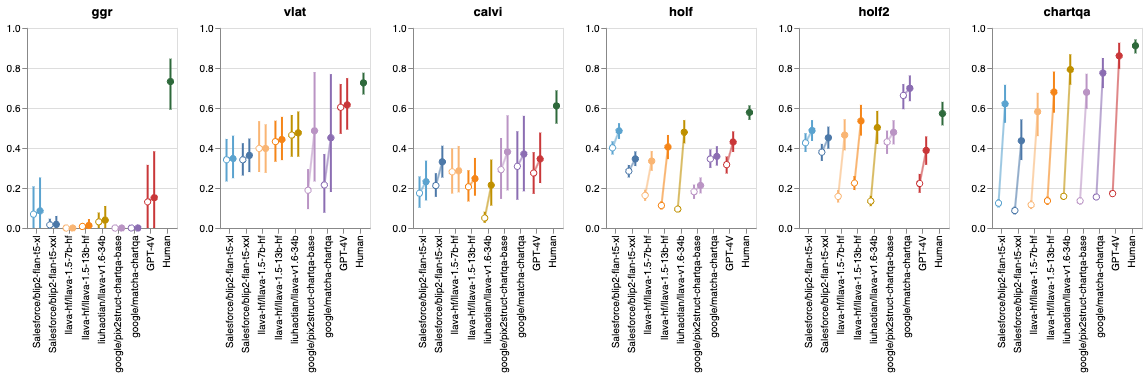

In [255]:
ci_df = ci_dfs[
    ((ci_dfs['scoring_type'] == 'valid_only') &
    (ci_dfs['agent_type'] == 'Human')) |
    (ci_dfs['agent_type'] != 'Human')
]


tests = ['ggr', 'vlat', 'calvi', 'holf', 'holf2',
       'chartqa-test-continuous-human']

plots = []
for test in tests:
    test_ci_df = ci_df[ci_df['test_type'] == test]
    if len(test) > 6:
        test = test[:7]
    
    plot = create_error_plot(test_ci_df, test)
    plot = plot.properties(width=150, height=200)
    plots.append(plot)

plots = alt.hconcat(*plots)
plots.save("./figures/human_machine_performance.pdf")
plots